In [182]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import holoviews as hv
from holoviews.operation.datashader import rasterize
import hvplot.xarray # noqa
import panel as pn
import fsspec

pn.extension('tabulator')
hv.extension('bokeh')

In [2]:
import h5py

In [3]:
headpath = "/home/lag36/scratch/lag36/2024-12-12_lLAG8_EZRDM_Run-02_3-Fiducials_Auto-Media-Switch/Barcodes"
df_2_1 = pd.read_hdf(headpath+'/barcode_output_df_fiducials_hamming-0_rm-1-28.hdf5')
bc_kymo_metadata_df = pd.read_hdf(headpath+"/kymograph_metadata_df.hdf5", key='data')
hdf5_metadata_df = pd.read_hdf("/home/lag36/scratch/lag36/2024-12-12_lLAG8_EZRDM_Run-02_3-Fiducials_Auto-Media-Switch/Barcodes/metadata.hdf5")
# df_2_1
df_lookup = (df_2_1
             .loc[:,['trenchid', 'Barcode Signal', 'Barcode', 'closest_match',  'barcode depth', 'Closest Hamming Distance', 'Category', 'barcode', 'barcodeid']]
             .merge(bc_kymo_metadata_df.groupby('trenchid').first().reset_index(),
                    left_on='trenchid',
                    right_on='trenchid', how='left')
                )

In [4]:
# Plotly version
microns_per_pixel = 0.105951961895293*2
max_x, max_y = 2960, 2960
trenchid = 3242
df_lookup.loc[df_lookup["trenchid"] == trenchid, :]
fov, x, y = df_lookup.loc[df_lookup["trenchid"] == trenchid, ["fov", "x (local)", "y (local)"]].values[0]
fov, x ,y
x /= microns_per_pixel
y /= microns_per_pixel

t = 14
file_index, image_index = hdf5_metadata_df.loc[(fov, t), ["File Index", "Image Index"]]

with h5py.File(headpath+"/hdf5/hdf5_"+str(file_index)+".hdf5", "r") as f:
    print
    print(f['RFP'][image_index].shape)
    
    # plt.imshow(f['RFP'][image_index])
    img = f['RFP'][image_index]
    # fig = go.Figure(data = go.Image(z=f['RFP'][image_index]))
    # fig.show(renderer='colab')

(2960, 2960)


In [5]:
import xarray

In [6]:
data = (xr
        .open_dataset(headpath+"/hdf5/hdf5_"+str(file_index)+".hdf5", phony_dims='sort')
        .swap_dims({'phony_dim_0':'time', 'phony_dim_1':'y', 'phony_dim_2':'x'})
        .assign_coords(time=np.arange(15, dtype=np.int16),
                       y=np.arange(2960, dtype=np.int16),
                       x=np.arange(2960, dtype=np.int16))
       )

In [120]:
'/home/lag36/scratch/lag36/2025-01-29_Microscopy-Test-Case/'

'/home/lag36/scratch/lag36/2024-12-12_lLAG8_EZRDM_Run-02_3-Fiducials_Auto-Media-Switch/Barcodes'

In [137]:
data.to_zarr('/home/lag36/scratch/lag36/2025-01-29_Microscopy-Test-Case/example_2.zarr')

In [138]:
xr.open_zarr('/home/lag36/scratch/lag36/2025-01-29_Microscopy-Test-Case/example.zarr')

<xarray.Dataset> Size: 789MB
Dimensions:  (time: 15, y: 2960, x: 2960)
Coordinates:
  * time     (time) uint16 30B 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14
  * x        (x) uint16 6kB 0 1 2 3 4 5 6 ... 2953 2954 2955 2956 2957 2958 2959
  * y        (y) uint16 6kB 0 1 2 3 4 5 6 ... 2953 2954 2955 2956 2957 2958 2959
Data variables:
    BF       (time, y, x) uint16 263MB dask.array<chunksize=(2, 370, 740), meta=np.ndarray>
    Cy5      (time, y, x) uint16 263MB dask.array<chunksize=(2, 370, 740), meta=np.ndarray>
    RFP      (time, y, x) uint16 263MB dask.array<chunksize=(2, 370, 740), meta=np.ndarray>

In [ ]:
# Generate it for 3 channels: RFP, GFP, and YFP
hvplot_app = {}

    hvplot_app[channel] = data[channel].hvplot.image(
        groupby='time',
        title='hvPlot App',
        cmap='viridis',
        # clim=(0, 20),
        data_aspect=1,
        # widget_location='bottom',
        rasterize=True
    )

# Display the app
hvplot_app

In [234]:
# Generate it for 3 channels: RFP, GFP, and YFP
hvplot_app = {}
for channel in ['BF', 'RFP', 'Cy5']:
    hvplot_app[channel] = data[channel].hvplot.image(
        groupby='time',
        title='hvPlot App',
        cmap='gray',
        # clim=(0, 20),
        data_aspect=1,
        # widget_location='bottom',
        rasterize=True
    ).opts(invert_yaxis=True)

rect = hv.Rectangles((x-7, y, x+9, y+170) ).opts(
    line_color='red', fill_alpha=0, line_width=2
)
# Display the app
hvplot_app

{'BF': :DynamicMap   [time],
 'RFP': :DynamicMap   [time],
 'Cy5': :DynamicMap   [time]}

In [227]:
hv_fovs = hvplot_app['BF']*rect + hvplot_app['Cy5']*rect + hvplot_app['RFP']*rect

In [155]:
# 
microns_per_pixel = 0.105951961895293*2
max_x, max_y = 2960, 2960
trenchid = 3242
df_lookup.loc[df_lookup["trenchid"] == trenchid, :]
fov, x, y = df_lookup.loc[df_lookup["trenchid"] == trenchid, ["fov", "x (local)", "y (local)"]].values[0]
fov, x ,y
x /= microns_per_pixel
y /= microns_per_pixel

In [173]:
x, y

(np.float64(2478.5), np.float64(2089.0))

In [171]:
t = 14
file_index, image_index = hdf5_metadata_df.loc[(fov, t), ["File Index", "Image Index"]]
hdf5_lookup_df = hdf5_metadata_df.loc[(fov, ), ["File Index", "Image Index"]]

In [200]:
# Get barcode kymos
### QC segmentation
import h5py
import matplotlib.pyplot as plt
import numpy as np

def show_kymograph(
        path_prefix,
        path_kymo_dir_prefix,
        channels,
        cmap,
        kymo_file_index,
        trench_index,
        t_indices,
        figsize,
        Barcode = None,
        barcode_phe = None #translated from seq barcode
        ):
    
    n_cycles_per_ch = 15 # TODO GENERALIZE
    imgs = []
    with h5py.File(path_prefix + path_kymo_dir_prefix + str(kymo_file_index) + ".hdf5", "r") as infile:
        for i_ch, ch in enumerate(channels):
            img = infile[ch][trench_index][t_indices[0]]
            for ind in t_indices[1:]:
                img_ind = infile[ch][trench_index][ind]
                img = np.concatenate((img, img_ind), axis=1)
            plt.figure(figsize=figsize)
            # Do not show axes ticks
            plt.xticks([])
            plt.yticks([])
            imgs.append(img)
            plt.imshow(img, cmap=cmap, aspect=1)
            # Annotate the kymo_file_index and the trench index at the bottom left corner
            plt.annotate(f'kymo_file_index: {kymo_file_index}, trench index: {trench_index}', (10, 15), color='white')
            # Annotate the cycle number at the bottom of each slice
            for i, ind in enumerate(t_indices):
                # plt.annotate(f'{ind}', (i*9+9/4, 160), color='white', fontsize=8) # 13 is the width of a slice
                plt.annotate(f'{ind}', (i*11+11/4, 160), color='white', fontsize=8) # 13 is the width of a slice
            # Annotate the Barcode bit at the bottom of each slice
            if Barcode is not None:
                
                for i, bit in enumerate(Barcode[i_ch*n_cycles_per_ch:(i_ch+1)*n_cycles_per_ch]):
                    # plt.annotate(f'{bit}', (i*9+9/3, 140), color='yellow', fontsize=8) # 13 is the width of a slice
                    plt.annotate(f'{bit}', (i*11+11/3, 140), color='yellow', fontsize=8) # 13 is the width of a slice
            # Annotate the barcode bit at the bottom of each slice
            if barcode_phe is not None:
                for i, bit in enumerate(barcode_phe[i_ch*n_cycles_per_ch:(i_ch+1)*n_cycles_per_ch]):
                    # plt.annotate(f'{bit}', (i*9+9/3, 120), color='red', fontsize=8) # 13 is the width of a slice
                    plt.annotate(f'{bit}', (i*11+11/3, 120), color='red', fontsize=8) # 13 is the width of a slice
            plt.show()
            plt.close()
    return imgs
def map_bc_to_pheno(barcode,
                    cycleorder = [0,1,6,7,12,13,18,19,24,25,4,5,10,11,16,
                                  2,3,8,9,14,15,20,21,26,27,17,22,23,28,29],
                    ):
    barcode_phe = [-1]*30
    for i, bit in enumerate(barcode):
        # print(i, bit)
        # Find the position of i in cycleorder
        i_phe = cycleorder.index(i)
        barcode_phe[i_phe] = bit
    barcode_phe = ''.join(barcode_phe)
    return barcode_phe

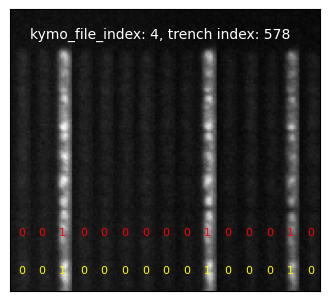

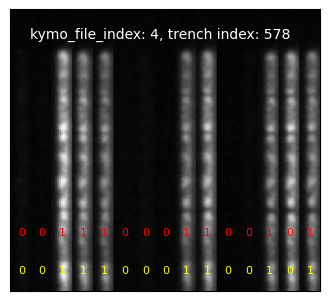

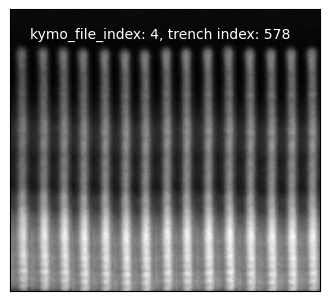

In [201]:
trenchid = 3242
bc_kymo_file_index, bc_trench_index, Barcode, barcode = df_lookup.loc[df_lookup['trenchid'] == trenchid, ['File Index', 'File Trench Index', 'Barcode', 'barcode']].values[0]
bc_kymo_file_index = int(bc_kymo_file_index)
bc_trench_index = int(bc_trench_index)
# barcode (lowercase) comes from sequencing (red)
# Barcode (uppercase) comes from trench signal (yellow)
# Barcode, barcode = df_lookup.loc[row, ['Barcode', 'barcode']]
barcode_phe = map_bc_to_pheno(barcode)
figsize = (4, 8)
path_prefix = headpath+"/"
path_kymo_dir_prefix = "kymograph/kymograph_"
# channels = ["BF", "RFP", "Cy5"]
channels = ["RFP", "Cy5"]
cmap = "gray"
t_indices = np.arange(0,15)
imgs = show_kymograph(path_prefix, path_kymo_dir_prefix, channels, cmap, bc_kymo_file_index, bc_trench_index, t_indices, figsize, Barcode, barcode_phe)
imgs_bf = show_kymograph(path_prefix, path_kymo_dir_prefix, ['BF'], cmap, bc_kymo_file_index, bc_trench_index, t_indices, figsize, None, None)

In [205]:
imgs += imgs_bf

In [206]:
imgs

[array([[1903, 1744, 1766, ..., 1589, 1544, 1520],
        [1705, 1792, 1868, ..., 1485, 1552, 1522],
        [1551, 1569, 1849, ..., 1639, 1528, 1626],
        ...,
        [1946, 1994, 1967, ..., 1968, 1790, 1885],
        [1812, 1970, 1821, ..., 1907, 1870, 1748],
        [1900, 1945, 2008, ..., 2055, 1660, 1792]], dtype=uint16),
 array([[ 3050,  3151,  2847, ...,  3039,  3098,  3056],
        [ 3110,  3191,  3159, ...,  3421,  2868,  3096],
        [ 3190,  2915,  3070, ...,  3017,  3228,  3300],
        ...,
        [ 3353,  3278,  3255, ..., 10055,  8286,  7262],
        [ 3203,  2863,  3315, ..., 10147,  7959,  6872],
        [ 3454,  3314,  3283, ...,  9819,  7698,  6296]], dtype=uint16),
 array([[ 3338,  3173,  3725, ...,  3364,  3254,  3459],
        [ 3238,  3461,  3011, ...,  3288,  3361,  3197],
        [ 3288,  3282,  3229, ...,  3212,  3130,  3390],
        ...,
        [12913, 12702, 12572, ..., 20378, 18247, 15539],
        [11777, 10985, 10349, ..., 20037, 17581, 1499

In [207]:
data_vars = {f'var_{i}': (('y', 'x'), img) for i, img in enumerate(imgs)}
dataset = xr.Dataset(data_vars)

In [235]:
hvplot_app_kymos = {}
for var in dataset.data_vars:
    hvplot_app_kymos[var] = dataset[var].hvplot.image(
        # groupby='time',
        # title='hvPlot App',
        cmap='gray',
        # clim=(0, 20),
        data_aspect=1,
        # hide colormap
        colorbar=False,
        # hide axes ticks and labels
        xaxis=None,
        yaxis=None,

        width = 150,
        height = 150,
        # widget_location='bottom',
        rasterize=True
    ).opts(invert_yaxis=True)

# Display the app
hvplot_app_kymos

{'var_0': :DynamicMap   [],
 'var_1': :DynamicMap   [],
 'var_2': :DynamicMap   []}

In [236]:
hv_fovs = hvplot_app['BF']*rect + hvplot_app['Cy5']*rect + hvplot_app['RFP']*rect

In [237]:
hv_kymos = hvplot_app_kymos['var_0']+hvplot_app_kymos['var_1']+hvplot_app_kymos['var_2']

In [240]:
hv_fovs + hv_kymos

:Layout
   .DynamicMap.I   :DynamicMap   [time]
      :Overlay
         .Image.I      :Image   [x,y]   (BF)
         .Rectangles.I :Rectangles   [x0,y0,x1,y1]
   .DynamicMap.II  :DynamicMap   [time]
      :Overlay
         .Image.I      :Image   [x,y]   (Cy5)
         .Rectangles.I :Rectangles   [x0,y0,x1,y1]
   .DynamicMap.III :DynamicMap   [time]
      :Overlay
         .Image.I      :Image   [x,y]   (RFP)
         .Rectangles.I :Rectangles   [x0,y0,x1,y1]
   .DynamicMap.IV  :DynamicMap   []
      :Image   [x,y]   (var_0)
   .DynamicMap.V   :DynamicMap   []
      :Image   [x,y]   (var_1)
   .DynamicMap.VI  :DynamicMap   []
      :Image   [x,y]   (var_2)